# Assignment 08: Species Distribution Modeling with elapid

## BIO597 Spatial Analysis of Biodiversity

Use `elapid` to prepare spatial data, fit a MaxEnt model, and ask how evaluation changes when we withhold whole geographic areas. You may reuse code from Lab08.

## Deliverable

Submit this completed notebook with maps, climate comparisons, ROC curves, an AUC summary table, and short written answers. Save your modeling points and AUC table. Use the lab's model defaults; no parameter search or suitability-raster export is required.


## 1. Import packages and load the occurrence records

Run this notebook from `docs/assignments`. The imports are provided so you can focus on the SDM workflow. If elapid is unavailable, use the same environment or installation instructions as the lab.

`np.random.seed(597)` makes the background draws repeatable when the notebook runs from top to bottom.


In [1]:
import elapid as ela
import numpy as np
import pandas as pd
import geopandas as gpd
import rasterio as rio
from rasterio import plot as rioplot
import matplotlib.pyplot as plt
from sklearn import metrics
from sklearn.metrics import RocCurveDisplay

np.random.seed(597)
amphibians = gpd.read_file("../data/amphibians.geojson")
amphibians["species"].value_counts().head(12)


species
Pseudacris crucifer          1839
Aquarana clamitans           1779
Anaxyrus americanus          1689
Boreorana sylvatica          1617
Lithobates catesbeianus      1487
Ambystoma maculatum          1317
Plethodon cinereus           1283
Lithobates palustris         1049
Dryophytes versicolor         790
Notophthalmus viridescens     611
Lithobates pipiens            326
Hemidactylium scutatum        233
Name: count, dtype: int64

## 2. Choose a species

Choose a common Maine amphibian other than the lab's pickerel frog (*Lithobates palustris*). Start with at least 200 records. Filter the occurrence table to your species and store the result as `species_points`.


In [2]:
target_species = "Ambystoma maculatum"

# Select your species and store a copy as species_points.
species_points = amphibians[amphibians["species"] == target_species].copy()

# Print the record count and coordinate reference system.
print(len(species_points))
species_points.crs

1317


<Geographic 2D CRS: EPSG:4326>
Name: WGS 84
Axis Info [ellipsoidal]:
- Lat[north]: Geodetic latitude (degree)
- Lon[east]: Geodetic longitude (degree)
Area of Use:
- name: World.
- bounds: (-180.0, -90.0, 180.0, 90.0)
Datum: World Geodetic System 1984 ensemble
- Ellipsoid: WGS 84
- Prime Meridian: Greenwich

**Why this species?** Give one biological reason for your choice. The spotted salamander is relatively common, but I know that salamanders have distinct habitat needs for breeding (eg, vernal pools) so they are likely affected by precipitation variables prior to breeding, along with temperature variables that may affect snow pack.

## 3. Set up the climate rasters

Use the same 19 Maine bioclimatic rasters as the lab. The filenames and readable column names are provided below. Their order matters: each label must describe the corresponding raster.


In [3]:
bioclim_names = {
    'wc2.1_2.5m_bio_1.tif':  'Annual mean temperature',
    'wc2.1_2.5m_bio_2.tif':  'Mean diurnal temperature range',
    'wc2.1_2.5m_bio_3.tif':  'Isothermality',
    'wc2.1_2.5m_bio_4.tif':  'Temperature seasonality',
    'wc2.1_2.5m_bio_5.tif':  'Max temperature, warmest month',
    'wc2.1_2.5m_bio_6.tif':  'Min temperature, coldest month',
    'wc2.1_2.5m_bio_7.tif':  'Annual temperature range',
    'wc2.1_2.5m_bio_8.tif':  'Mean temperature, wettest quarter',
    'wc2.1_2.5m_bio_9.tif':  'Mean temperature, driest quarter',
    'wc2.1_2.5m_bio_10.tif': 'Mean temperature, warmest quarter',
    'wc2.1_2.5m_bio_11.tif': 'Mean temperature, coldest quarter',
    'wc2.1_2.5m_bio_12.tif': 'Annual precipitation',
    'wc2.1_2.5m_bio_13.tif': 'Precipitation, wettest month',
    'wc2.1_2.5m_bio_14.tif': 'Precipitation, driest month',
    'wc2.1_2.5m_bio_15.tif': 'Precipitation seasonality',
    'wc2.1_2.5m_bio_16.tif': 'Precipitation, wettest quarter',
    'wc2.1_2.5m_bio_17.tif': 'Precipitation, driest quarter',
    'wc2.1_2.5m_bio_18.tif': 'Precipitation, warmest quarter',
    'wc2.1_2.5m_bio_19.tif': 'Precipitation, coldest quarter',
}

rasters = [f"../data/bioclim_ME/{var}" for var in bioclim_names]
labels = list(bioclim_names.values())


## 4. Map the records over temperature

Open `rasters[0]` (annual mean temperature), plot it with `rioplot.show()`, and overlay your species' points. Reproject the points to the raster CRS when plotting, as in the lab. Keep this first raster path as `mean_temp_raster` for sampling.


In [4]:
print(target_species)
print(type(target_species))

Ambystoma maculatum
<class 'str'>


<>:14: SyntaxWarning: invalid escape sequence '\ '
<>:14: SyntaxWarning: invalid escape sequence '\ '
/tmp/ipykernel_1851/2995913677.py:14: SyntaxWarning: invalid escape sequence '\ '
  ax.set_title('$Ambystoma \ maculatum$ observations')
/srv/conda/envs/notebook/lib/python3.13/site-packages/matplotlib/colors.py:816: RuntimeWarning: overflow encountered in multiply
  xa *= self.N


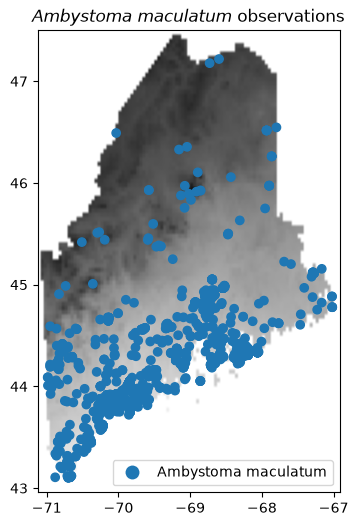

In [5]:
mean_temp_raster = rasters[0]

# Plot annual mean temperature and overlay species_points.
fig, ax = plt.subplots(figsize=(6,6))
with rio.open(mean_temp_raster, 'r') as src:
    
    # this plots the mean annual temperature data
    # low temps are dark grey, high temps are light grey
    rioplot.show(src, ax=ax, cmap="gray")
    
    # overlay the ariolimax data
    species_points.to_crs(src.crs).plot(column='species', ax=ax, legend=True)
# Add a title naming your species.
    ax.set_title('$Ambystoma \ maculatum$ observations')

**Interpretation:** Are records spread across Maine or concentrated in particular places? Why might a gap in records fail to indicate a true absence? Records are mostly concentrated in southern Maine, especially along the coast, and in Baxter State Park. There are a couple of points in northern Maine. I suspect that the concentration of points is due to observer effort rather than true occurrence.

## 5. Compare two background samples

Draw 1,000 points with `ela.sample_raster()` and another 1,000 with `ela.sample_bias_file()`, using annual mean temperature as the bias file. Drop duplicate geometries in each sample, following the lab, and report the remaining counts. Map the two samples side by side.

The biased sample favors cells with larger temperature values. This is a demonstration of sampling bias; temperature alone does not establish where observers actually searched.


Num. pseudoabsence points: 917
Num. pseudoabsence_bias points: 908


<Axes: >

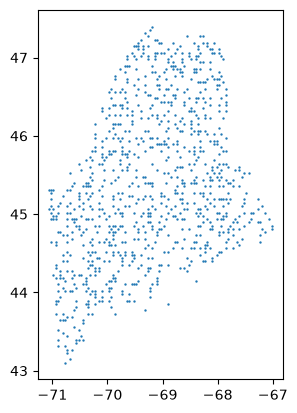

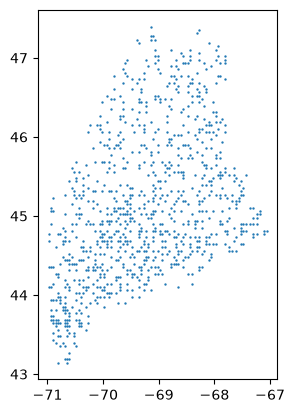

In [6]:
count = 1000

# Create pseudoabsence with ela.sample_raster().
pseudoabsence = ela.sample_raster(mean_temp_raster, count)

# Create pseudoabsence_bias with ela.sample_bias_file().
pseudoabsence_bias = ela.sample_bias_file(mean_temp_raster, count)

# Drop duplicate points, print the remaining counts, and map both samples.
pseudoabsence.drop_duplicates(inplace=True)
pseudoabsence_bias.drop_duplicates(inplace=True)

print("Num. pseudoabsence points:", pseudoabsence.describe()["count"])
print("Num. pseudoabsence_bias points:", pseudoabsence_bias.describe()["count"])

pseudoabsence.plot(markersize=0.5)
pseudoabsence_bias.plot(markersize=0.5)

**Interpretation:** How do the two geographic samples differ? Explain why background choice can change the species–climate relationship learned by a model. Fig 1 has records evenly spread across space, whereas Fig 2 has them clustered in areas with higher temperatures. If observers are more likely to search in areas with higher temperatures, then a bias file should account for that. 

Choose one sample for the remaining analysis and keep it fixed. The line below uses the uniform sample; change it to `pseudoabsence_bias` if you choose the biased sample.

**Background choice and justification:**
I chose to use the bias file to account for sampling bias.

In [7]:
background_points = pseudoabsence_bias


## 6. Extract climate values with `ela.annotate()`

Annotate `species_points.geometry` and your chosen `background_points` using `rasters`, `labels`, `drop_na=True`, and `quiet=True`. Store the results as `presence` and `background`. Report the number of usable rows in each table.

Annotation means extracting raster values at point locations. `drop_na=True` removes points falling on raster NoData cells.


In [8]:
# Annotate presence and background points, following Lab08.
presence = ela.annotate(
    species_points.geometry, # geometry column from geodf
    rasters, # list of file paths to bioclim rasters
    labels=labels, # labels we made earlier for each raster
    drop_na=True,
    quiet=True,
)

background = ela.annotate(
    background_points,
    rasters,
    labels=labels,
    drop_na=True,
    quiet=True,
)


In [9]:
# Print the usable counts and display presence.head().
print("Num. presence points:", presence.describe()["Annual mean temperature"]["count"])
print("Num. background points:", background.describe()["Annual mean temperature"]["count"])

Num. presence points: 1214.0
Num. background points: 908.0


## 7. Compare recorded and available environments

Use the plotting recipe below to compare annual mean temperature, annual precipitation, and precipitation seasonality. These are the same three variables considered in Lab07. Density-scaled histograms let us compare shapes despite different sample sizes.


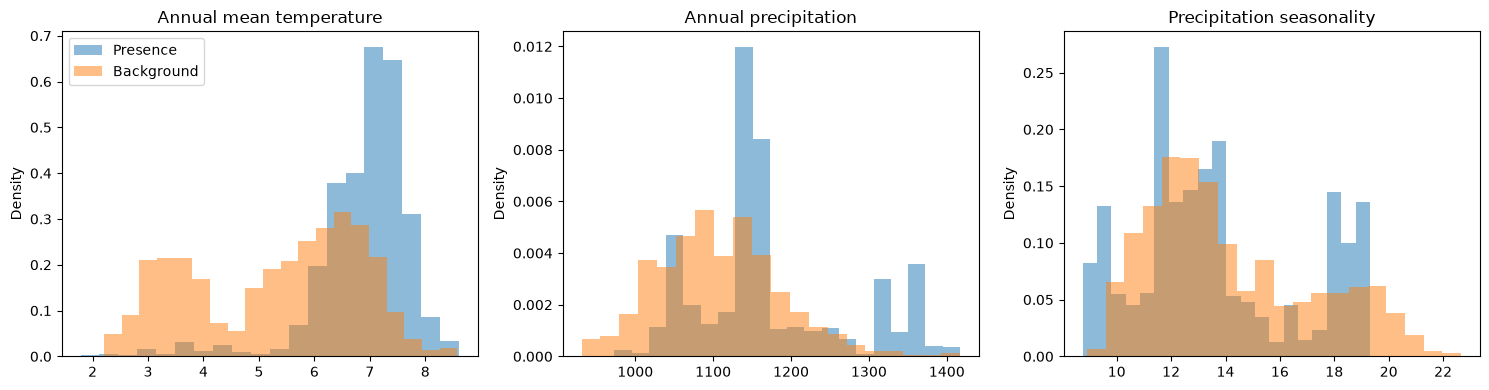

In [10]:
comparison_labels = [labels[0], labels[11], labels[14]]
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

for label, ax in zip(comparison_labels, axes):
    ax.hist(presence[label], bins=20, density=True, alpha=0.5, label="Presence")
    ax.hist(background[label], bins=20, density=True, alpha=0.5, label="Background")
    ax.set_title(label)
    ax.set_ylabel("Density")

axes[0].legend()
plt.tight_layout()
plt.show()


**Interpretation:** Choose one variable. Does your species' recorded environment differ from the sampled background? Describe the pattern without assuming it proves a habitat preference. Annual mean temperature seems like the clear winner because my species' presence points are skewed toward high temperatures.

## 8. Calculate geographic sample weights

Following the lab, use `ela.distance_weights(..., n_neighbors=-1)` to calculate a `SampleWeight` column separately for presence and background. Pass points projected to `EPSG:26919`, which uses meters. Plot presence points colored by their weights.

The weights give relatively isolated observations more influence than observations in dense clusters. They do not turn an unobserved location into a confirmed absence.


<Axes: >

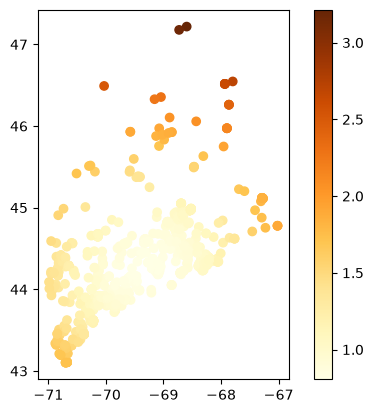

In [11]:
# Calculate presence["SampleWeight"] using presence.to_crs("EPSG:26919").
presence['SampleWeight'] = ela.distance_weights(presence.to_crs('EPSG:26919'), n_neighbors=-1)
# Calculate background["SampleWeight"] the same way.
background['SampleWeight'] = ela.distance_weights(background.to_crs('EPSG:26919'), n_neighbors=-1)
# Plot the presence weights with a legend.
presence.plot(column='SampleWeight', legend=True, cmap='YlOrBr')

**Interpretation:** Where are the largest weights? Why would decimal degrees be a poor unit for the distance calculations? The largest weights are at the far edges of the cluster, farther away from other points. Decimal degrees is a poor unit for distance calculations because it increases/decreases unevenly based on latitude/longitude.

## 9. Stack the tables and define predictors

Use `ela.stack_geodataframes(presence, background, add_class_label=True)` and project the result to `EPSG:26919`. Call the result `merged` and display the counts in its `class` column.

`class` is 1 for presence and 0 for background. Select only the named climate columns as predictors. `SampleWeight`, class labels, geometry, and later split labels must stay out of the predictor table.


In [12]:
# Stack presence and background as merged, then project it to EPSG:26919.
merged = ela.stack_geodataframes(
    presence,
    background,
    add_class_label=True,
).to_crs('EPSG:26919')

# Display the counts of each class.
print(merged['class'].value_counts())

X = merged[labels]
y = merged["class"]
sample_weight = merged["SampleWeight"]


class
1    1214
0     908
Name: count, dtype: int64


## 10. Fit MaxEnt and calculate a training AUC

Create `maxent = ela.MaxentModel()` and fit it with `X`, `y`, and `sample_weight=sample_weight`. Predict scores for `X`.

This first check uses the same rows for learning and evaluation, as in the lab's “naive” model. It is a **training score**, not a test of new locations.

**ROC AUC** measures how well scores rank presence above background. A value near 0.5 indicates little ranking ability; a higher value indicates better separation of these labels. The ROC curve shows the tradeoff as we change the cutoff for calling a score high: more recorded presences exceed the cutoff, but more background points may exceed it too. AUC does not establish true occupancy probability.


In [13]:
maxent = ela.MaxentModel()
maxent.set_params(n_cpus=4)

# Fit maxent with X, y, and sample_weight.
maxent.fit(X, y, sample_weight=sample_weight)

# Predict X and store the scores as naive_prediction.
naive_prediction = maxent.predict(X)

# Calculate naive_auc with metrics.roc_auc_score(y, naive_prediction).
naive_auc = metrics.roc_auc_score(y, naive_prediction)
# Also calculate naive_weighted_auc using sample_weight=sample_weight.
naive_weighted_auc = metrics.roc_auc_score(y, naive_prediction, sample_weight=sample_weight)
# Print both scores and plot a ROC curve with RocCurveDisplay.from_predictions().
print(naive_auc)
print(naive_weighted_auc)

0.9225985927759109
0.9112047461198529


**Interpretation:** Why might evaluating the same rows used to fit a model give an overly encouraging impression of performance? Because the model isn't being tested on its ability to predict suitability given brand new data.

## 11. Make a geographic train/test split

Use `ela.checkerboard_split(merged, grid_size=50_000)` to divide points into alternating 50 km squares. This distance is in meters because `merged` is projected.

Check the class counts in both groups: each needs presence and background rows to calculate AUC. The provided plotting recipe adds a split label for display only.


Training labels:
class
1    822
0    455
Name: count, dtype: int64
Test labels:
class
0    453
1    390
Name: count, dtype: int64


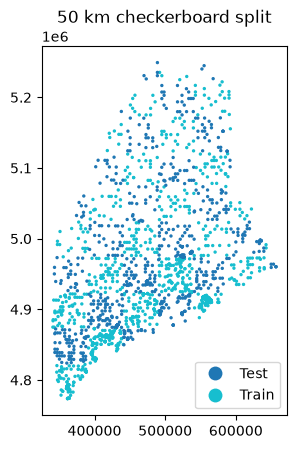

In [14]:
grid_size = 50_000
train, test = ela.checkerboard_split(merged, grid_size=grid_size)
print("Training labels:")
print(train["class"].value_counts())
print("Test labels:")
print(test["class"].value_counts())

train["split"] = "Train"
test["split"] = "Test"
checker = ela.stack_geodataframes(train, test)
checker.plot(column="split", markersize=2, legend=True)
plt.title("50 km checkerboard split")
plt.show()


## 12. Refit using training points and evaluate test points

Build training and test predictor tables using only `labels`, as below. Refit `maxent` on the training rows and their weights, then predict the test rows. Calculate unweighted and weighted test AUCs, storing them as `checker_auc` and `checker_weighted_auc`. Plot the test ROC curve.

In weighted AUC, test weights affect the contribution of each test row. They do not mean the model learned from the test labels.


Unweighted test checkerboard AUC score: 0.672
Weighted test checkerboard AUC score: 0.650


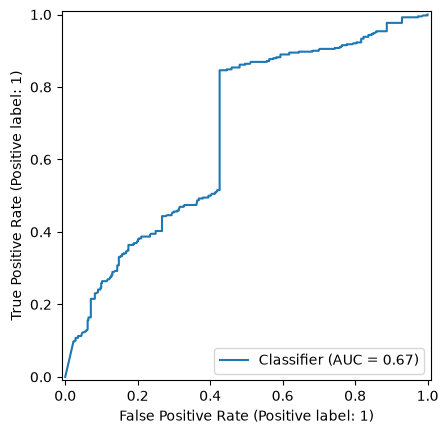

In [15]:
Xtrain = train[labels]
ytrain = train["class"]
weight_train = train["SampleWeight"]
Xtest = test[labels]
ytest = test["class"]
weight_test = test["SampleWeight"]

# Fit maxent using only Xtrain, ytrain, and weight_train.
Xtrain = train.drop(columns=['class', 'SampleWeight', 'split'])
ytrain = train['class']
sample_weight_train = train['SampleWeight']

Xtest = test.drop(columns=['class', 'SampleWeight', 'split'])
ytest = test['class']
sample_weight_test = test['SampleWeight']

# Predict Xtest and calculate checker_auc and checker_weighted_auc.
maxent.fit(Xtrain, ytrain, sample_weight=sample_weight_train)
ypred = maxent.predict(Xtest)

# Print the scores and plot the test ROC curve.
test_unweighted_auc = metrics.roc_auc_score(ytest, ypred)
test_weighted_auc = metrics.roc_auc_score(ytest, ypred, sample_weight=sample_weight_test)

print(f"Unweighted test checkerboard AUC score: {test_unweighted_auc:0.3f}")
print(f"Weighted test checkerboard AUC score: {test_weighted_auc:0.3f}")
RocCurveDisplay.from_predictions(ytest, ypred)

## Apply the trained model to the ME clipped rasters

<>:12: SyntaxWarning: invalid escape sequence '\ '
<>:12: SyntaxWarning: invalid escape sequence '\ '
/tmp/ipykernel_1851/2926781517.py:12: SyntaxWarning: invalid escape sequence '\ '
  ax.set_title('$Ambystoma\ maculatum$ suitability')


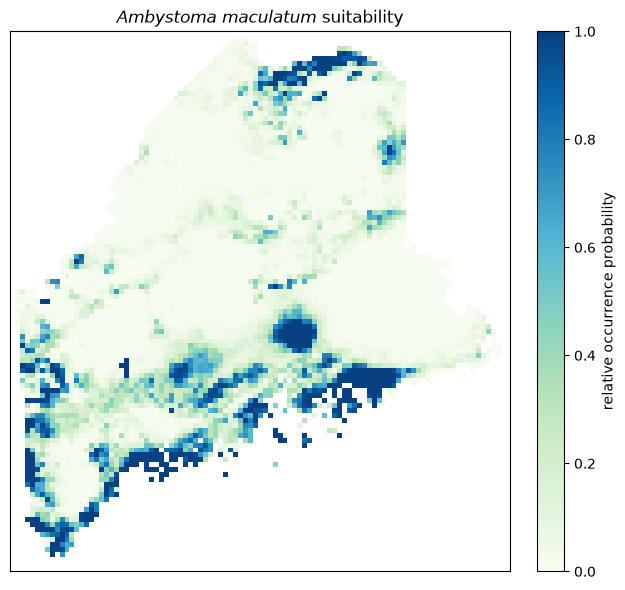

In [16]:
output_raster = "ambystoma-maxent-predictions.tif"
# Use ela.apply_model_to_rasters() to apply the fitted model to the raster stack
# and write the result to the output_raster file
ela.apply_model_to_rasters(maxent, rasters, output_raster, quiet=True)

# use rio.open() to read the predicted tif back into memory
with rio.open(output_raster, 'r') as src:
    pred = src.read(1, masked=True)
# and plot it with imshow()
fig, ax = plt.subplots(1, 1, figsize=(7, 6), dpi=100)
plot = ax.imshow(pred, vmin=0, vmax=1, cmap='GnBu')
ax.set_title('$Ambystoma\ maculatum$ suitability')
ax.set_xticks([])
ax.set_yticks([])
cbar = plt.colorbar(plot, ax=ax, label="relative occurrence probability", pad=0.04)
plt.tight_layout()

**Interpretation:** Did test AUC differ from training AUC? Describe what each score evaluates. A lower test score does not automatically prove that spatial autocorrelation caused the difference: the training size and environments also changed. A higher test score does not automatically establish a reliable map.

Yes, the the test AUC was 0.76 and the train AUC was 0.89. The test AUC was lower because the model had to predict suitability of brand new points that likely had variation associated with them that hadn't been fully accounted for in the training data.

## 13. Give the other squares a turn

For a simple two-fold spatial cross-validation, reverse the roles: create a new MaxEnt model, train it using `Xtest`, `ytest`, and `weight_test`, then evaluate its predictions for `Xtrain`. Store the unweighted and weighted scores as `reverse_auc` and `reverse_weighted_auc`.

No new background draw or checkerboard split is needed.


In [17]:
# Create reverse_model with the same settings.
# Fit on Xtest with ytest and weight_test; predict Xtrain.
maxent.fit(Xtest, ytest, sample_weight=sample_weight_test)
ypred = maxent.predict(Xtrain)
# Calculate reverse_auc and reverse_weighted_auc against ytrain.
reverse_auc = metrics.roc_auc_score(ytrain, ypred)
reverse_weighted_auc = metrics.roc_auc_score(ytrain, ypred, sample_weight=sample_weight_train)
# Print the scores.
print(reverse_auc)
print(reverse_weighted_auc)

0.49469532900189833
0.48944363919631984


**Interpretation:** Were the two directions equally easy to predict? Suggest one geographic or biological reason for a difference. Swapping the regions gives each group a turn as test data; it does not remove every source of observation bias.

The AUC was much much lower this time. I'm wondering if it's because most of the coastline consisted of training data, but I'm not exactly sure how that would play out in the model

## 14. Inspect one buffered leave-one-out split

The lab also demonstrates buffered leave-one-out validation. For each test presence, it removes nearby training points so the model must predict farther from its training data.

Run the code below to inspect **one split**, using a 50 km buffer. No repeated model fitting is required here. `next()` takes just the first split that the splitter produces. This visualization is not a complete validation or an AUC estimate.


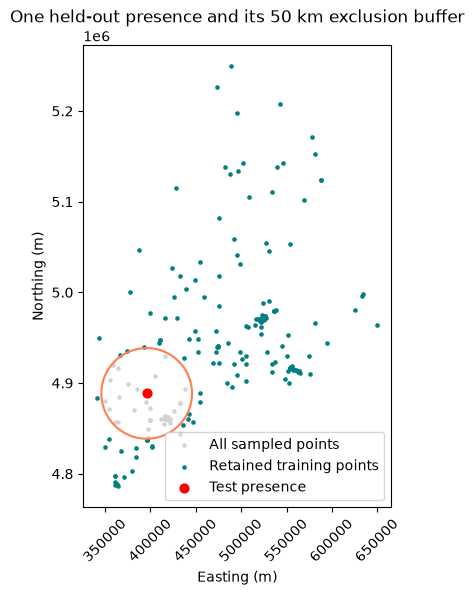

In [18]:
subset = merged.sample(n=min(200, len(merged)), random_state=597).reset_index(drop=True)
distance = 50_000
bloo = ela.BufferedLeaveOneOut(distance=distance)
train_idx, test_idx = next(bloo.split(subset, class_label="class"))
buffer_train = subset.iloc[train_idx]
buffer_test = subset.iloc[test_idx]

fig, ax = plt.subplots(figsize=(6, 6))
subset.plot(ax=ax, color="lightgray", markersize=5, label="All sampled points")
buffer_train.plot(ax=ax, color="teal", markersize=5, label="Retained training points")
buffer_test.buffer(distance).boundary.plot(ax=ax, color="coral")
buffer_test.plot(ax=ax, color="red", markersize=40, label="Test presence")
ax.legend()
ax.set_xlabel("Easting (m)")
ax.set_ylabel("Northing (m)")
ax.tick_params(axis="x", labelrotation=45)
ax.set_title("One held-out presence and its 50 km exclusion buffer")
plt.show()


**Interpretation:** What happened to points inside the buffer? How does this test a different prediction question from randomly withholding records? Explain why a single held-out presence cannot by itself give a ROC AUC.

The points inside the buffer were not used to train the red point, which reduces spatial autocorrelation in the model. The single witheld presence cannot give a ROC AUC because it is just a single point that the model predicts, and many more points are needed to generage a distribution of model error.

## 15. Summarize and save your results

Make a three-row table with evaluation names, unweighted AUCs, and weighted AUCs:

* Training rows scored by the all-data model.
* First checkerboard direction: train on `train`, evaluate `test`.
* Reversed direction: train on `test`, evaluate `train`.

Save it as `Assignment08_auc_scores.csv`, without a DataFrame index. Save `merged` as `Assignment08_modeling_points.gpkg` using `driver="GPKG"`, preserving its geometry, climate columns, labels, weights, and projected CRS.


In [19]:
# Build an AUC summary table from the six scores you stored.
auc_summary = pd.DataFrame({
    'Model': [
        'Naive unweighted',
        'Naive weighted',
        'Test unweighted',
        'Test weighted',
        'Reverse unweighted',
        'Reverse weighted'
    ],
    'AUC': [
        naive_auc,
        naive_weighted_auc,
        test_unweighted_auc,
        test_weighted_auc,
        reverse_auc,
        reverse_weighted_auc
    ]
})
# Display it and save it to Assignment08_auc_scores.csv.
print(auc_summary)
auc_summary.to_csv("Assignment08_auc_scores.csv", index=False)

# Save merged to Assignment08_modeling_points.gpkg.
merged.to_file("Assignment08_modeling_points.gpkg", driver="GPKG")

                Model       AUC
0    Naive unweighted  0.922599
1      Naive weighted  0.911205
2     Test unweighted  0.672098
3       Test weighted  0.649803
4  Reverse unweighted  0.494695
5    Reverse weighted  0.489444


## Final reflection

Answer each question in two or three sentences, using your results.

1. Which preparation tasks did elapid simplify compared with earlier labs? It was much easier to join the occurrence data with the raster climate data and ensure that they were in the same crs.
2. What do background sampling, geographic sample weights, and spatial train/test splitting each change? Background sampling affects the data that goes into the model before it is split into train/test datasets. Geographic sample weights give more leverage to certain points, which can help even out the influence of certain geographic areas that are underrepresented in the data. Spatial train/test splitting helps account for spatial autocorrelation so that points don't train models for points that are in close proximity.
3. Why do high AUC and a convincing ROC curve not establish a probability that your species occurs at a location?
High AUC and convincing ROC curves could be influenced by all of the above factors (background sampling, sample weights, and train/test splitting), so you could be comparing apples to oranges unless the ROC curves being compared have similar methodologies for these steps.
4. What additional data or evaluation would most improve confidence in predictions for your species? Detection data! Effort! How likely are we to miss detection a species if it is present?

## Submit your work

Restart the kernel and run the notebook from top to bottom. Check your figures, AUC table, saved points, and written answers. Commit and push the completed notebook and the two output files to your class GitHub repository.

```bash
git add docs/assignments/Assignment-08-SDM-Software.ipynb docs/assignments/Assignment08_auc_scores.csv docs/assignments/Assignment08_modeling_points.gpkg
git commit -m "Complete elapid SDM assignment"
git push
```

## References

* [elapid geospatial tools](https://earth-chris.github.io/elapid/module/geo/)
* [elapid MaxEnt model](https://earth-chris.github.io/elapid/sdm/maxent/)
* [elapid spatial train/test splitting](https://earth-chris.github.io/elapid/module/train_test_split/)
